In [ ]:
import pandas as pd
import numpy as np

column_names = ["duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes",
                "land", "wrong_fragment", "urgent", "hot", "num_failed_logins", "logged_in",
                "num_compromised", "root_shell", "su_attempted", "num_root",
                "num_file_creations", "num_shells", "num_access_files", "num_outbound_cmds",
                "is_host_login", "is_guest_login", "count", "srv_count", "serror_rate",
                "srv_serror_rate", "rerror_rate", "srv_rerror_rate", "same_srv_rate",
                "diff_srv_rate", "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count",
                "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
                "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate",
                "dst_host_serror_rate", "dst_host_srv_serror_rate", "dst_host_rerror_rate",
                "dst_host_srv_rerror_rate", "label", "difficulty_level"]

train_df = pd.read_csv(r"/content/KDDTrain+.txt", sep="\t", names=column_names)
test_df = pd.read_csv(r"/content/KDDTest+.txt", sep="\t", names=column_names)

print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))
print("Columns:", train_df.shape[1])

train_df[["duration", "protocol_type", "service", "flag", "src_bytes", "label"]].head()

Training rows: 125973
Testing rows: 22544
Columns: 43


,duration,protocol_type,service,flag,src_bytes,label
0,0,tcp,ftp_data,SF,491,normal
1,0,udp,other,SF,146,normal
2,0,tcp,private,S0,0,neptune
3,0,tcp,http,SF,232,normal
4,0,tcp,http,SF,199,normal


In [ ]:
train_df["attack"] = 0
train_df.loc[train_df["label"].str.lower() != "normal", "attack"] = 1

test_df["attack"] = 0
test_df.loc[test_df["label"].str.lower() != "normal", "attack"] = 1

print("Training set:")
print(train_df["attack"].value_counts())
print()
print("Testing set:")
print(test_df["attack"].value_counts())

Training set:
attack
0    67343
1    58630
Name: count, dtype: int64

Testing set:
attack
1    12833
0     9711
Name: count, dtype: int64


In [ ]:
print("Test shape:", test_df.shape)
print()
print("Test label values:")
print(test_df["label"].value_counts().head(8))
print()
print("Missing values in training set:", train_df.isnull().sum().sum())
print("Missing values in testing set:", test_df.isnull().sum().sum())
print()
test_df[["duration", "protocol_type", "service", "flag", "src_bytes", "label", "difficulty_level"]].head()

Test shape: (22544, 44)

Test label values:
label
Attack    12833
Normal     9711
Name: count, dtype: int64

Missing values in training set: 0
Missing values in testing set: 22544



,duration,protocol_type,service,flag,src_bytes,label,difficulty_level
0,0,tcp,private,REJ,0,Attack,NaN
1,0,tcp,private,REJ,0,Attack,NaN
2,2,tcp,ftp_data,SF,12983,Normal,NaN
3,0,icmp,eco_i,SF,20,Attack,NaN
4,1,tcp,telnet,RSTO,0,Attack,NaN


In [ ]:
# join train and test so both get exactly the same columns
train_df["is_train"] = 1
test_df["is_train"] = 0
all_df = pd.concat([train_df, test_df], ignore_index=True)

# turn the 3 text columns into 1/0 columns
all_df = pd.get_dummies(all_df, columns=["protocol_type", "service", "flag"])

# remove columns we do not need
all_df = all_df.drop(columns=["label", "difficulty_level"])

# separate train and test again
train_new = all_df[all_df["is_train"] == 1].drop(columns=["is_train"])
test_new = all_df[all_df["is_train"] == 0].drop(columns=["is_train"])

# inputs (X) and answers (y)
X_train = train_new.drop(columns=["attack"]).astype(float)
y_train = train_new["attack"]
X_test = test_new.drop(columns=["attack"]).astype(float)
y_test = test_new["attack"]

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (125973, 123)
X_test shape: (22544, 123)


In [ ]:
from sklearn.preprocessing import StandardScaler

print("y_train counts:")
print(y_train.value_counts())
print()
print("y_test counts:")
print(y_test.value_counts())
print()

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Biggest number before scaling:", X_train.values.max())
print("Biggest number after scaling:", round(X_train_scaled.max(), 2))
print("Inputs per row:", X_train_scaled.shape[1])

y_train counts:
attack
0    67343
1    58630
Name: count, dtype: int64

y_test counts:
attack
1    12833
0     9711
Name: count, dtype: int64

Biggest number before scaling: 1379963888.0
Biggest number after scaling: 354.93
Inputs per row: 123


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

number_of_inputs = X_train_scaled.shape[1]
print("Inputs per connection:", number_of_inputs)

model = Sequential()
model.add(Input(shape=(number_of_inputs,)))
model.add(Dense(32, activation="relu"))
model.add(Dense(16, activation="relu"))
model.add(Dense(1, activation="sigmoid"))

model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

history = model.fit(X_train_scaled, y_train, epochs=10, batch_size=64, validation_split=0.2)

loss, accuracy = model.evaluate(X_test_scaled, y_test)
print("Test accuracy:", round(accuracy * 100, 2), "%")

Inputs per connection: 123
Epoch 1/10
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9794 - loss: 0.0627 - val_accuracy: 0.9925 - val_loss: 0.0276
Epoch 2/10
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9918 - loss: 0.0247 - val_accuracy: 0.9934 - val_loss: 0.0230
Epoch 3/10
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9926 - loss: 0.0209 - val_accuracy: 0.9929 - val_loss: 0.0217
Epoch 4/10
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9932 - loss: 0.0197 - val_accuracy: 0.9937 - val_loss: 0.0198
Epoch 5/10
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9938 - loss: 0.0181 - val_accuracy: 0.9949 - val_loss: 0.0174
Epoch 6/10
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9940 - loss: 0.0172 - val_accuracy: 0.9940 - val_loss: 0.0184
Epoch 7/10
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9947 - loss: 0.0157 - val_accuracy: 0.9953 - val_loss: 0.0163
Epoch 8/10
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accurac

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

predictions = (model.predict(X_test_scaled) > 0.5).astype(int)

print("Confusion matrix (rows = real, columns = predicted):")
print(confusion_matrix(y_test, predictions))
print()
print(classification_report(y_test, predictions, target_names=["normal", "attack"]))

705/705 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
Confusion matrix (rows = real, columns = predicted):
[[8991  720]
 [4071 8762]]

              precision    recall  f1-score   support

      normal       0.69      0.93      0.79      9711
      attack       0.92      0.68      0.79     12833

    accuracy                           0.79     22544
   macro avg       0.81      0.80      0.79     22544
weighted avg       0.82      0.79      0.79     22544



In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from sklearn.metrics import confusion_matrix

number_of_inputs = X_train_scaled.shape[1]

model_single = Sequential()
model_single.add(Input(shape=(number_of_inputs,)))
model_single.add(Dense(1, activation="sigmoid"))

model_single.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

model_single.fit(X_train_scaled, y_train, epochs=10, batch_size=64, validation_split=0.2)

loss1, acc1 = model_single.evaluate(X_test_scaled, y_test)
print("Single-layer test accuracy:", round(acc1 * 100, 2), "%")

predictions1 = (model_single.predict(X_test_scaled) > 0.5).astype(int)
print(confusion_matrix(y_test, predictions1))

Epoch 1/10
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9478 - loss: 0.1711 - val_accuracy: 0.9708 - val_loss: 0.1006
Epoch 2/10
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9711 - loss: 0.0937 - val_accuracy: 0.9704 - val_loss: 0.0879
Epoch 3/10
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - accuracy: 0.9716 - loss: 0.0852 - val_accuracy: 0.9711 - val_loss: 0.0814
Epoch 4/10
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9718 - loss: 0.0806 - val_accuracy: 0.9729 - val_loss: 0.0782
Epoch 5/10
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9718 - loss: 0.0781 - val_accuracy: 0.9714 - val_loss: 0.0760
Epoch 6/10
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9720 - loss: 0.0765 - val_accuracy: 0.9727 - val_loss: 0.0750
Epoch 7/10
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9717 - loss: 0.0756 - val_accuracy: 0.9727 - val_loss: 0.0748
Epoch 8/10
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9722 - loss: 0.0749 - 

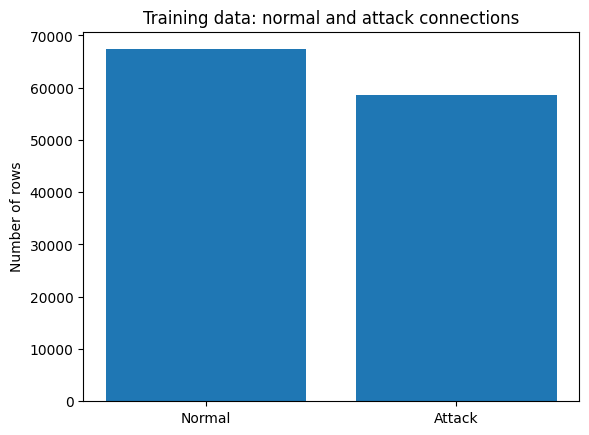

In [ ]:
 import matplotlib.pyplot as plt

# Graph 1: normal vs attack rows in the training data
counts = train_df["attack"].value_counts().sort_index()
plt.bar(["Normal", "Attack"], counts.values)
plt.title("Training data: normal and attack connections")
plt.ylabel("Number of rows")
plt.show()

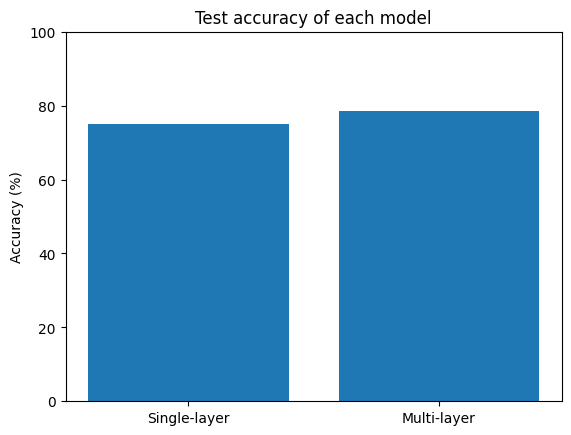

In [ ]:
# Graph 2: comparing the two models
plt.bar(["Single-layer", "Multi-layer"], [75.03, 78.62])
plt.title("Test accuracy of each model")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.show()

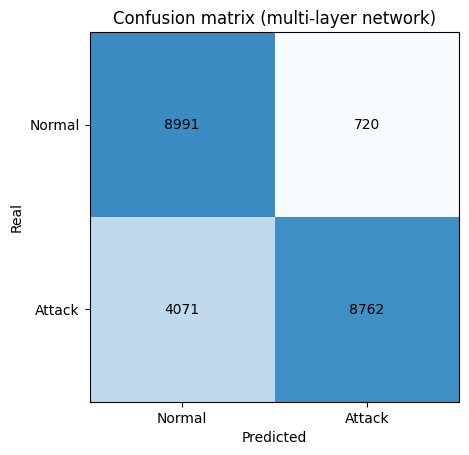

In [ ]:
# Graph 3: confusion matrix of the multi-layer network
cm = confusion_matrix(y_test, predictions)
plt.imshow(cm, cmap="Blues", vmax=cm.max() * 1.5)
plt.xticks([0, 1], ["Normal", "Attack"])
plt.yticks([0, 1], ["Normal", "Attack"])
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i][j], ha="center", va="center")
plt.title("Confusion matrix (multi-layer network)")
plt.xlabel("Predicted")
plt.ylabel("Real")
plt.show()

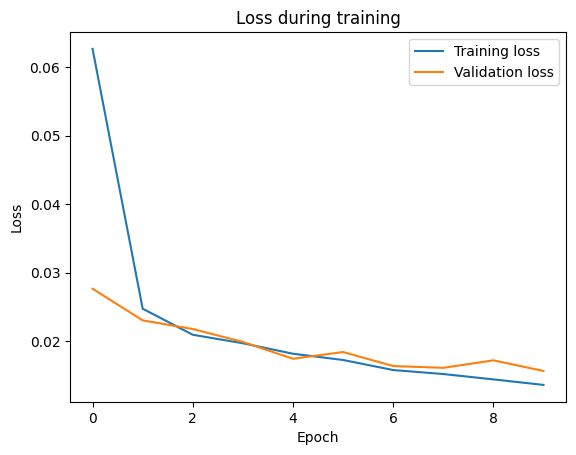

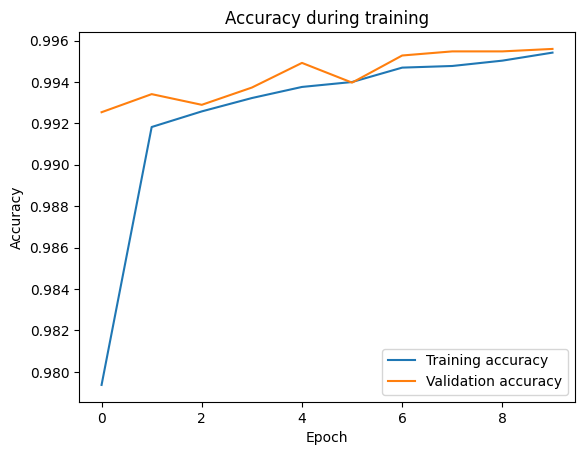

In [ ]:
# Graph 4: training curves
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.title("Loss during training")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.title("Accuracy during training")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [ ]:
from flask import Flask, request, render_template_string
import threading
import random

# Lists for the dropdown boxes (taken from the training columns)
protocol_list = []
service_list = []
flag_list = []

for col in X_train.columns:
    if col.startswith("protocol_type_"):
        protocol_list.append(col.replace("protocol_type_", ""))
    if col.startswith("service_"):
        service_list.append(col.replace("service_", ""))
    if col.startswith("flag_"):
        flag_list.append(col.replace("flag_", ""))

# A default row: the typical (median) value of every column
default_row = X_train.median()
for col in X_train.columns:
    if col.startswith("protocol_type_") or col.startswith("service_") or col.startswith("flag_"):
        default_row[col] = 0

# The web page (HTML)
page = """
<!DOCTYPE html>
<html>
<head>
<title>Network Intrusion Detector</title>
<style>
body { font-family: Arial; background: #f2f4f8; margin: 0; padding: 20px; }
.box { background: white; max-width: 650px; margin: auto; padding: 25px; border-radius: 10px; }
h1 { color: #1a3c6e; }
label { display: block; margin-top: 12px; font-weight: bold; }
input, select { width: 100%; padding: 8px; margin-top: 4px; box-sizing: border-box; }
button { margin-top: 18px; margin-right: 8px; padding: 10px 18px; background: #1a3c6e; color: white; border: none; border-radius: 6px; cursor: pointer; }
.result { margin-top: 20px; padding: 15px; border-radius: 8px; font-size: 18px; }
.attack { background: #fde2e2; color: #a40000; }
.normal { background: #dff5e1; color: #1b6e2a; }
</style>
</head>
<body>
<div class="box">
<h1>Network Intrusion Detector</h1>
<p>Enter details of a network connection, or try a random real connection from the test data.</p>

<form method="post">

<label>Protocol type</label>
<select name="protocol_type">
{% for p in protocol_list %}
<option value="{{ p }}" {% if p == form_values['protocol_type'] %}selected{% endif %}>{{ p }}</option>
{% endfor %}
</select>

<label>Service</label>
<select name="service">
{% for s in service_list %}
<option value="{{ s }}" {% if s == form_values['service'] %}selected{% endif %}>{{ s }}</option>
{% endfor %}
</select>

<label>Flag</label>
<select name="flag">
{% for f in flag_list %}
<option value="{{ f }}" {% if f == form_values['flag'] %}selected{% endif %}>{{ f }}</option>
{% endfor %}
</select>

<label>Duration (seconds)</label>
<input type="number" step="any" name="duration" value="{{ form_values['duration'] }}">

<label>Bytes sent (src_bytes)</label>
<input type="number" step="any" name="src_bytes" value="{{ form_values['src_bytes'] }}">

<label>Bytes received (dst_bytes)</label>
<input type="number" step="any" name="dst_bytes" value="{{ form_values['dst_bytes'] }}">

<label>Connections to the same host in the last 2 seconds (count)</label>
<input type="number" step="any" name="count" value="{{ form_values['count'] }}">

<label>Failed login attempts</label>
<input type="number" step="any" name="num_failed_logins" value="{{ form_values['num_failed_logins'] }}">

<label>SYN error rate (0 to 1)</label>
<input type="number" step="any" name="serror_rate" value="{{ form_values['serror_rate'] }}">

<button type="submit" name="mode" value="form">Check this connection</button>
<button type="submit" name="mode" value="random">Try a random real test connection</button>

</form>

{% if result_text %}
<div class="result {{ result_class }}">
{{ result_text }}
{% if extra_text %}<br><small>{{ extra_text }}</small>{% endif %}
</div>
{% endif %}

</div>
</body>
</html>
"""

app = Flask(__name__)

@app.route("/", methods=["GET", "POST"])
def home():
    result_text = ""
    result_class = ""
    extra_text = ""

    form_values = {"protocol_type": "tcp", "service": "http", "flag": "SF",
                   "duration": 0, "src_bytes": 232, "dst_bytes": 8153,
                   "count": 5, "num_failed_logins": 0, "serror_rate": 0.0}

    if request.method == "POST":
        mode = request.form["mode"]

        if mode == "form":
            # keep what the user typed
            for name in form_values:
                form_values[name] = request.form[name]

            # start from the default row and change the chosen details
            row = default_row.copy()
            row["duration"] = float(form_values["duration"])
            row["src_bytes"] = float(form_values["src_bytes"])
            row["dst_bytes"] = float(form_values["dst_bytes"])
            row["count"] = float(form_values["count"])
            row["num_failed_logins"] = float(form_values["num_failed_logins"])
            row["serror_rate"] = float(form_values["serror_rate"])
            row["protocol_type_" + form_values["protocol_type"]] = 1
            row["service_" + form_values["service"]] = 1
            row["flag_" + form_values["flag"]] = 1

            row_df = pd.DataFrame([row]).astype(float)
            row_scaled = scaler.transform(row_df)
            chance = float(model.predict(row_scaled, verbose=0)[0][0])
            extra_text = "Only 9 details were entered. All other details use typical values."

        else:
            # pick a random real connection from the test data
            index = random.randint(0, len(X_test_scaled) - 1)
            row_scaled = X_test_scaled[index].reshape(1, -1)
            chance = float(model.predict(row_scaled, verbose=0)[0][0])

            real_answer = int(y_test.iloc[index])
            if real_answer == 1:
                real_word = "ATTACK"
            else:
                real_word = "NORMAL"

            if (chance > 0.5) == (real_answer == 1):
                extra_text = "Real answer: " + real_word + ". The network was RIGHT."
            else:
                extra_text = "Real answer: " + real_word + ". The network was WRONG."

        # make the result message
        if chance > 0.5:
            result_text = "ATTACK (chance of attack: " + str(round(chance * 100, 1)) + "%)"
            result_class = "attack"
        else:
            result_text = "NORMAL (chance of attack: " + str(round(chance * 100, 1)) + "%)"
            result_class = "normal"

    return render_template_string(page,
                                  protocol_list=protocol_list,
                                  service_list=service_list,
                                  flag_list=flag_list,
                                  form_values=form_values,
                                  result_text=result_text,
                                  result_class=result_class,
                                  extra_text=extra_text)

print("The web app is ready")

The web app is ready


In [ ]:
def run_app():
    app.run(port=5000)

server_thread = threading.Thread(target=run_app)
server_thread.start()

In [ ]:
import subprocess
import time

!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
!chmod +x cloudflared

log_file = open("tunnel_log.txt", "w")
tunnel = subprocess.Popen(["./cloudflared", "tunnel", "--url", "http://127.0.0.1:5000"],
                          stdout=log_file, stderr=log_file)

link = ""
for i in range(30):
    time.sleep(1)
    log_text = open("tunnel_log.txt").read()
    for word in log_text.split():
        if word.startswith("https://") and word.endswith(".trycloudflare.com"):
            link = word
    if link != "":
        break

print("Your page link:", link)

cloudflared: Text file busy
Your page link: https://protecting-combinations-prague-pit.trycloudflare.com
